In [1]:
from pathlib import Path
from collections import Counter
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile
from tqdm.auto import tqdm

import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", "CUDA" if torch.cuda.is_available() else "CPU")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_theme(style="whitegrid")

PyTorch: 2.14.0+cpu
Torchvision: 0.29.0+cpu
Device: CPU


In [2]:
PROJECT_DIR = Path.cwd().parent

print("Project directory:", PROJECT_DIR)
print("\nContents:")

for item in PROJECT_DIR.iterdir():
    print(item.name, "(folder)" if item.is_dir() else "(file)")

Project directory: c:\Users\divya\OneDrive\Desktop\CV_task_i2v

Contents:
.venv (folder)
dataset (folder)
models (folder)
notebooks (folder)
outputs (folder)
readme.md (file)
report (folder)
src (folder)


In [3]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

DATA_DIR = PROJECT_DIR / "dataset" / "vehicle_dataset"

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"

print("Project:", PROJECT_DIR)
print("Dataset:", DATA_DIR)
print("Train exists:", TRAIN_DIR.exists())
print("Validation exists:", VAL_DIR.exists())

assert TRAIN_DIR.exists(), "Train folder not found!"
assert VAL_DIR.exists(), "Validation folder not found!"

print("\nTrain classes:")
print(sorted([p.name for p in TRAIN_DIR.iterdir() if p.is_dir()]))

print("\nValidation classes:")
print(sorted([p.name for p in VAL_DIR.iterdir() if p.is_dir()]))

Project: c:\Users\divya\OneDrive\Desktop\CV_task_i2v
Dataset: c:\Users\divya\OneDrive\Desktop\CV_task_i2v\dataset\vehicle_dataset
Train exists: True
Validation exists: True

Train classes:
['auto-rickshaw', 'bicycle', 'bus', 'car', 'e-rickshaw', 'mini-bus', 'mini-truck', 'motorcycle', 'rickshaw', 'tractor', 'truck', 'van']

Validation classes:
['auto-rickshaw', 'bicycle', 'bus', 'car', 'e-rickshaw', 'mini-bus', 'mini-truck', 'motorcycle', 'rickshaw', 'tractor', 'truck', 'van']


### Class Distribution and Sample Inventory
Count valid image files across all categories in both the training and validation sets to inspect dataset size and check for class imbalance.

In [4]:
# Count images in each class

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

def get_image_paths(folder):
    return sorted([
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ])

train_counts = {}
val_counts = {}

for class_dir in sorted(TRAIN_DIR.iterdir()):
    if class_dir.is_dir():
        train_counts[class_dir.name] = len(
            get_image_paths(class_dir)
        )

for class_dir in sorted(VAL_DIR.iterdir()):
    if class_dir.is_dir():
        val_counts[class_dir.name] = len(
            get_image_paths(class_dir)
        )

class_names = sorted(train_counts.keys())

inventory = pd.DataFrame({
    "Class": class_names,
    "Train Images": [train_counts[c] for c in class_names],
    "Validation Images": [val_counts.get(c, 0) for c in class_names]
})

inventory["Total Images"] = (
    inventory["Train Images"] + inventory["Validation Images"]
)

print("Number of classes:", len(class_names))
print("Total training images:", inventory["Train Images"].sum())
print("Total validation images:", inventory["Validation Images"].sum())
print("Total images:", inventory["Total Images"].sum())

display(inventory)

Number of classes: 12
Total training images: 2719
Total validation images: 765
Total images: 3484


,Class,Train Images,Validation Images,Total Images
0,auto-rickshaw,448,137,585
1,bicycle,263,69,332
2,bus,213,71,284
3,car,117,35,152
4,e-rickshaw,97,6,103
5,mini-bus,12,1,13
6,mini-truck,387,102,489
7,motorcycle,245,69,314
8,rickshaw,24,12,36
9,tractor,81,3,84


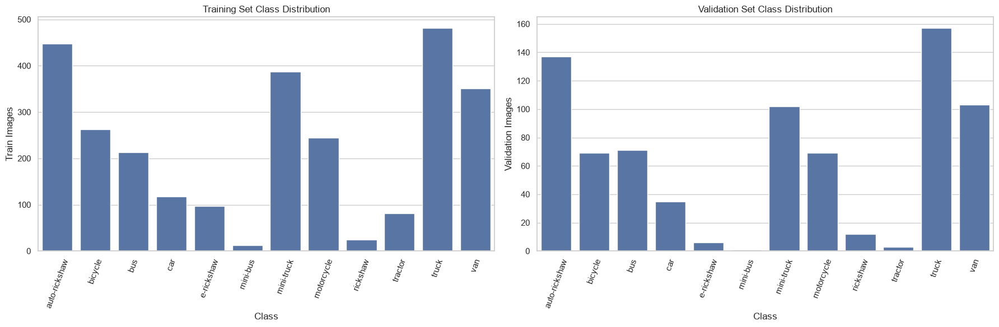

In [5]:
# Visualizing class distribution

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(
    data=inventory,
    x="Class",
    y="Train Images",
    ax=axes[0]
)
axes[0].set_title("Training Set Class Distribution")
axes[0].tick_params(axis="x", rotation=70)

sns.barplot(
    data=inventory,
    x="Class",
    y="Validation Images",
    ax=axes[1]
)
axes[1].set_title("Validation Set Class Distribution")
axes[1].tick_params(axis="x", rotation=70)

plt.tight_layout()
plt.show()

### Image Metadata & Corruption Audit
Inspect image resolutions, file formats, color channels (modes), and readability to detect corrupt files and establish appropriate resizing parameters.

In [6]:
# Inspecting image dimensions and formats

def inspect_images(split_dir, split_name):
    records = []

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        for img_path in get_image_paths(class_dir):
            try:
                with Image.open(img_path) as img:
                    records.append({
                        "split": split_name,
                        "class": class_dir.name,
                        "path": str(img_path),
                        "width": img.width,
                        "height": img.height,
                        "format": img.format,
                        "mode": img.mode,
                        "readable": True
                    })

            except Exception as e:
                records.append({
                    "split": split_name,
                    "class": class_dir.name,
                    "path": str(img_path),
                    "width": None,
                    "height": None,
                    "format": None,
                    "mode": None,
                    "readable": False
                })

    return records


records = []

records.extend(inspect_images(TRAIN_DIR, "train"))
records.extend(inspect_images(VAL_DIR, "val"))

image_df = pd.DataFrame(records)

print("Images inspected:", len(image_df))
print("\nImage formats:")
display(image_df["format"].value_counts(dropna=False).to_frame("Count"))

print("\nImage modes:")
display(image_df["mode"].value_counts(dropna=False).to_frame("Count"))

print("\nImage dimensions (most common):")
display(
    image_df.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(15)
    .to_frame("Count")
)

print("\nUnreadable images:", (~image_df["readable"]).sum())

Images inspected: 3484

Image formats:


,Count
format,
JPEG,1869
PNG,1615



Image modes:


,Count
mode,
RGB,3484



Image dimensions (most common):


,,Count
width,height,
195,79,7
194,79,5
193,79,5
195,78,5
196,80,4
52,46,4
196,79,4
64,74,3
31,59,3



Unreadable images: 0


### Anomaly Detection: Low Resolution & Extreme Aspect Ratios
Detect potential low-quality images by identifying samples under 64 pixels in either dimension or exhibiting extreme aspect ratios.

In [7]:
# checking for suspicious image dimensions

valid_images = image_df[image_df["readable"]].copy()

valid_images["aspect_ratio"] = (
    valid_images["width"] / valid_images["height"]
)

print("Smallest width:", valid_images["width"].min())
print("Smallest height:", valid_images["height"].min())

print("\nImages smaller than 64 pixels in either dimension:")
display(
    valid_images[
        (valid_images["width"] < 64) |
        (valid_images["height"] < 64)
    ][["class", "width", "height", "path"]].head(20)
)

print("\nExtreme aspect ratios (below 0.3 or above 3.0):")
display(
    valid_images[
        (valid_images["aspect_ratio"] < 0.3) |
        (valid_images["aspect_ratio"] > 3.0)
    ][["class", "width", "height", "path"]].head(20)
)

Smallest width: 16
Smallest height: 21

Images smaller than 64 pixels in either dimension:


,class,width,height,path
36,auto-rickshaw,52,46,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...
37,auto-rickshaw,51,57,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...
39,auto-rickshaw,62,80,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...
43,auto-rickshaw,59,269,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...
44,auto-rickshaw,52,66,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...
45,auto-rickshaw,34,97,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...
49,auto-rickshaw,43,55,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...
51,auto-rickshaw,62,79,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...
54,auto-rickshaw,42,50,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...
55,auto-rickshaw,62,59,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...



Extreme aspect ratios (below 0.3 or above 3.0):


,class,width,height,path
43,auto-rickshaw,59,269,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...
59,auto-rickshaw,61,271,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...
71,auto-rickshaw,264,81,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...
77,auto-rickshaw,60,275,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...
81,auto-rickshaw,50,266,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...
90,auto-rickshaw,58,269,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...
104,auto-rickshaw,60,263,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...
124,auto-rickshaw,60,271,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...
127,auto-rickshaw,61,269,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...
129,auto-rickshaw,61,276,c:\Users\divya\OneDrive\Desktop\CV_task_i2v\da...


In [8]:
# Random image samples from each class

def show_class_samples(split_dir, samples_per_class=4, seed=42):
    rng = random.Random(seed)

    classes = sorted([
        p for p in split_dir.iterdir()
        if p.is_dir()
    ])

    fig, axes = plt.subplots(
        len(classes),
        samples_per_class,
        figsize=(14, 3 * len(classes))
    )

    if samples_per_class == 1:
        axes = np.array(axes).reshape(-1, 1)

    for row, class_dir in enumerate(classes):

        image_paths = get_image_paths(class_dir)

        selected = rng.sample(
            image_paths,
            min(samples_per_class, len(image_paths))
        )

        for col in range(samples_per_class):

            ax = axes[row, col]

            if col < len(selected):
                img_path = selected[col]

                try:
                    img = Image.open(img_path).convert("RGB")

                    ax.imshow(img)
                    ax.set_title(
                        f"{class_dir.name}\n{img.size}",
                        fontsize=9
                    )

                except Exception:
                    ax.set_title("Could not load")

            ax.axis("off")

    plt.tight_layout()
    plt.show()

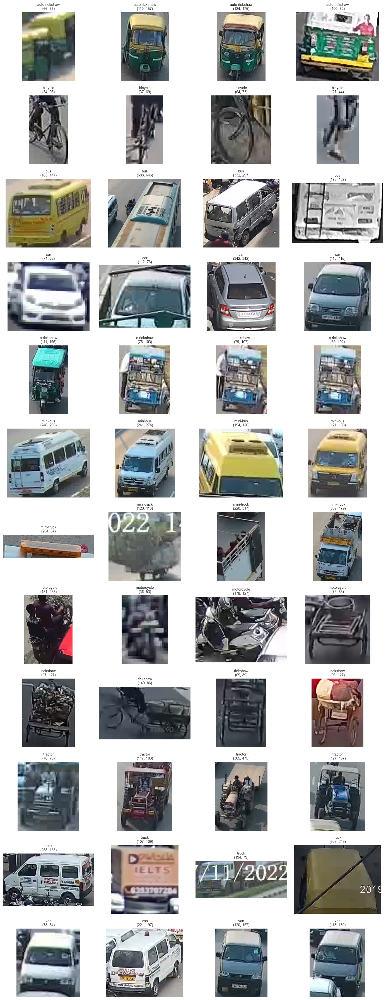

In [9]:
show_class_samples(TRAIN_DIR, samples_per_class=4)

### Outlier Visual Inspection
Visualize identified low-resolution and extreme aspect ratio images to determine whether they contain recognizable vehicle features or represent corrupt data to drop.

In [10]:
suspicious = valid_images[
    (valid_images["width"] < 64) |
    (valid_images["height"] < 64) |
    (valid_images["aspect_ratio"] < 0.3) |
    (valid_images["aspect_ratio"] > 3.0)
].copy()

print("Number of suspicious dimension/aspect-ratio images:",
      len(suspicious))

Number of suspicious dimension/aspect-ratio images: 681


In [11]:
def show_suspicious_images(df, n=20, seed=42):

    sample = df.sample(
        min(n, len(df)),
        random_state=seed
    )

    cols = 5
    rows = int(np.ceil(len(sample) / cols))

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(15, 3 * rows)
    )

    axes = np.array(axes).reshape(-1)

    for ax, (_, row) in zip(axes, sample.iterrows()):

        try:
            img = Image.open(row["path"]).convert("RGB")

            ax.imshow(img)
            ax.set_title(
                f'{row["class"]}\n'
                f'{row["width"]}×{row["height"]}',
                fontsize=9
            )

        except Exception:
            ax.set_title("Error")

        ax.axis("off")

    for ax in axes[len(sample):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

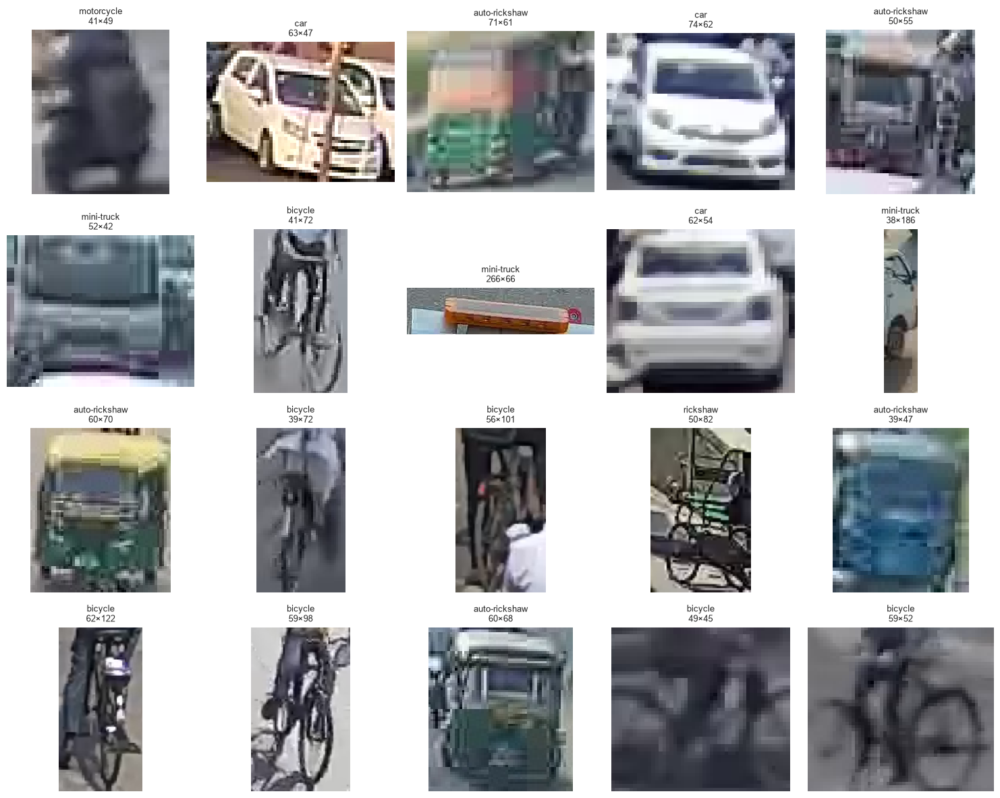

In [12]:
show_suspicious_images(suspicious, n=20)

### CleanVision

In [13]:
from cleanvision import Imagelab

print("CleanVision imported successfully.")

CleanVision imported successfully.


In [14]:
imagelab_train = Imagelab(
    data_path=str(TRAIN_DIR)
)

imagelab_train.find_issues()

Reading images from c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/train
Checking for dark, light, odd_aspect_ratio, low_information, exact_duplicates, near_duplicates, blurry, grayscale, odd_size images ...


Computing scores:   0%|          | 0/2719 [00:00<?, ?it/s]

Computing hashes:   0%|          | 0/2719 [00:00<?, ?it/s]

Issue checks completed. 143 issues found in the dataset. To see a detailed report of issues found, use imagelab.report().


Issues found in images in order of severity in the dataset

|    | issue_type       |   num_images |
|---:|:-----------------|-------------:|
|  0 | odd_aspect_ratio |           56 |
|  1 | near_duplicates  |           49 |
|  2 | odd_size         |           32 |
|  3 | blurry           |            6 |
|  4 | dark             |            0 |
|  5 | low_information  |            0 |
|  6 | light            |            0 |
|  7 | grayscale        |            0 |
|  8 | exact_duplicates |            0 | 

----------------- odd_aspect_ratio images ------------------

Number of examples with this issue: 56
Examples representing most severe instances of this issue:



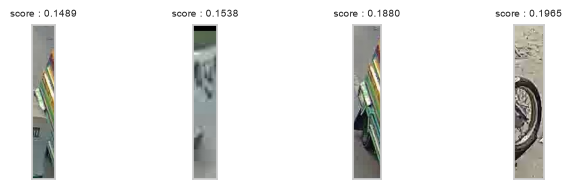

------------------ near_duplicates images ------------------

Number of examples with this issue: 49
Examples representing most severe instances of this issue:

Set: 0


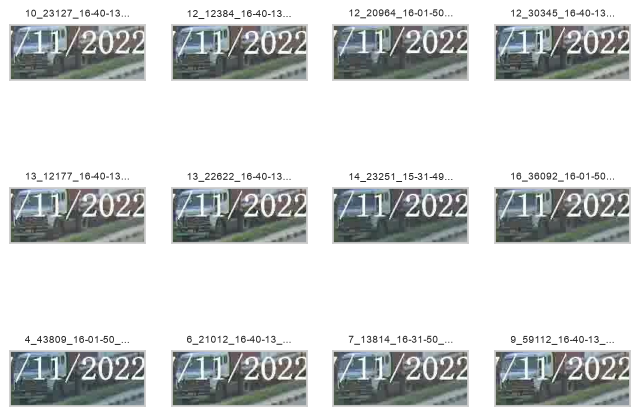

Set: 1


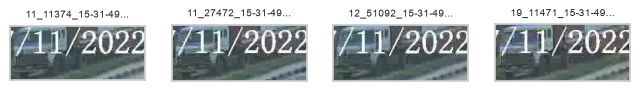

Set: 2


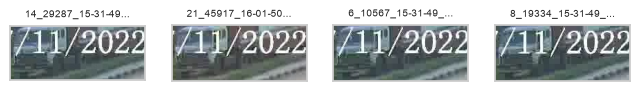

Set: 3


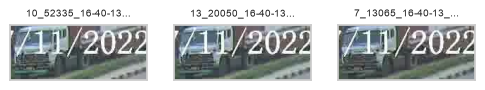

--------------------- odd_size images ----------------------

Number of examples with this issue: 32
Examples representing most severe instances of this issue:



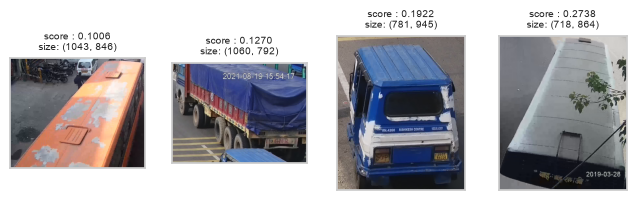

---------------------- blurry images -----------------------

Number of examples with this issue: 6
Examples representing most severe instances of this issue:



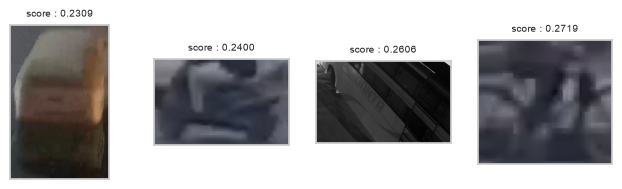

In [15]:
imagelab_train.report()

In [16]:
issues_train = imagelab_train.issues

print(type(issues_train))
display(issues_train)

<class 'pandas.DataFrame'>


,odd_size_score,is_odd_size_issue,odd_aspect_ratio_score,is_odd_aspect_ratio_issue,low_information_score,is_low_information_issue,light_score,is_light_issue,grayscale_score,is_grayscale_issue,dark_score,is_dark_issue,blurry_score,is_blurry_issue,exact_duplicates_score,is_exact_duplicates_issue,near_duplicates_score,is_near_duplicates_issue
c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/train/auto-rickshaw/0_00000028.jpg,0.391029,True,0.827357,False,0.901840,False,0.921931,False,1,False,0.871124,False,0.513936,False,1.0,False,1.0,False
c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/train/auto-rickshaw/0_00000029.jpg,0.442524,True,0.847482,False,0.906447,False,0.917402,False,1,False,0.874915,False,0.510236,False,1.0,False,1.0,False
c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/train/auto-rickshaw/0_00000041.jpg,0.771481,False,0.812821,False,0.890477,False,0.890781,False,1,False,0.867083,False,0.509790,False,1.0,False,1.0,False
c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/train/auto-rickshaw/0_00000074.jpg,0.771481,False,0.812821,False,0.895419,False,0.901353,False,1,False,0.864247,False,0.511728,False,1.0,False,1.0,False
c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/train/auto-rickshaw/0_00000131.jpg,0.712173,False,0.845103,False,0.882110,False,0.897619,False,1,False,0.843038,False,0.486095,False,1.0,False,1.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/train/van/9_2out06-30-08293.png,0.936321,False,0.611321,False,0.937135,False,0.908597,False,1,False,0.990773,False,0.593992,False,1.0,False,1.0,False
c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/train/van/9_2out07-00-06152.png,0.920742,False,0.649635,False,0.941788,False,0.900454,False,1,False,0.990818,False,0.594459,False,1.0,False,1.0,False
c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/train/van/9_2out07-00-06203.png,0.932699,False,0.630189,False,0.935827,False,0.879378,False,1,False,0.992530,False,0.597500,False,1.0,False,1.0,False
c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/train/van/9_2out07-00-10166.png,0.920944,False,0.772908,False,0.928239,False,0.849415,False,1,False,0.944567,False,0.580622,False,1.0,False,1.0,False


In [17]:
issues_train.to_csv(
    PROJECT_DIR / "outputs" / "cleanvision_train_issues.csv",
    index=False
)

print("Saved CleanVision training report.")

Saved CleanVision training report.


In [18]:
imagelab_val = Imagelab(
    data_path=str(VAL_DIR)
)

imagelab_val.find_issues()

Reading images from c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/val
Checking for dark, light, odd_aspect_ratio, low_information, exact_duplicates, near_duplicates, blurry, grayscale, odd_size images ...


Computing scores:   0%|          | 0/765 [00:00<?, ?it/s]

Computing hashes:   0%|          | 0/765 [00:00<?, ?it/s]

Issue checks completed. 34 issues found in the dataset. To see a detailed report of issues found, use imagelab.report().


Issues found in images in order of severity in the dataset

|    | issue_type       |   num_images |
|---:|:-----------------|-------------:|
|  0 | odd_aspect_ratio |           23 |
|  1 | odd_size         |            7 |
|  2 | near_duplicates  |            4 |
|  3 | dark             |            0 |
|  4 | light            |            0 |
|  5 | blurry           |            0 |
|  6 | low_information  |            0 |
|  7 | grayscale        |            0 |
|  8 | exact_duplicates |            0 | 

----------------- odd_aspect_ratio images ------------------

Number of examples with this issue: 23
Examples representing most severe instances of this issue:



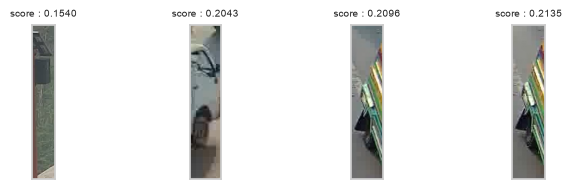

--------------------- odd_size images ----------------------

Number of examples with this issue: 7
Examples representing most severe instances of this issue:



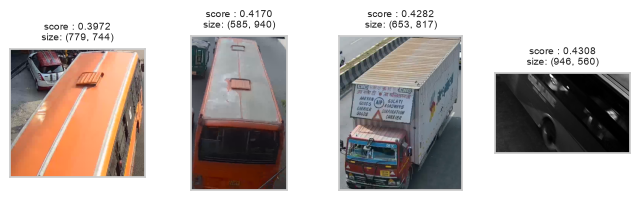

------------------ near_duplicates images ------------------

Number of examples with this issue: 4
Examples representing most severe instances of this issue:

Set: 0


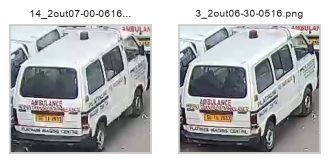

Set: 1


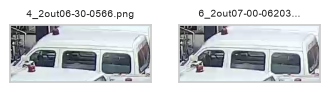

In [19]:
imagelab_val.report()

In [20]:
issues_val = imagelab_val.issues

display(issues_val)

,odd_size_score,is_odd_size_issue,odd_aspect_ratio_score,is_odd_aspect_ratio_issue,low_information_score,is_low_information_issue,light_score,is_light_issue,grayscale_score,is_grayscale_issue,dark_score,is_dark_issue,blurry_score,is_blurry_issue,exact_duplicates_score,is_exact_duplicates_issue,near_duplicates_score,is_near_duplicates_issue
c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/val/auto-rickshaw/0_00000057.jpg,0.764929,False,0.997475,False,0.895194,False,0.903057,False,1,False,0.829898,False,0.491401,False,1.0,False,1.0,False
c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/val/auto-rickshaw/0_1271_16-40-13_003304.jpg,0.975812,False,0.798701,False,0.912570,False,0.882037,False,1,False,0.976477,False,0.546706,False,1.0,False,1.0,False
c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/val/auto-rickshaw/0_14533_16-40-13_020234.jpg,0.939129,False,0.845455,False,0.907081,False,0.856454,False,1,False,0.878422,False,0.525607,False,1.0,False,1.0,False
c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/val/auto-rickshaw/0_2out06-30-0886.png,0.959458,False,0.720280,False,0.895328,False,0.794399,False,1,False,0.879935,False,0.488491,False,1.0,False,1.0,False
c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/val/auto-rickshaw/0_48798_14-31-49_031221.jpg,0.911075,False,0.626582,False,0.901913,False,0.915363,False,1,False,0.975021,False,0.495322,False,1.0,False,1.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/val/van/9_10626_16-40-13_016301.jpg,0.998403,False,0.808989,False,0.908049,False,0.875982,False,1,False,0.999056,False,0.526102,False,1.0,False,1.0,False
c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/val/van/9_13666_16-40-13_006278.jpg,0.941750,False,0.786325,False,0.904423,False,0.821074,False,1,False,0.990550,False,0.472503,False,1.0,False,1.0,False
c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/val/van/9_17858_10-21-08_009794.jpg,0.822061,False,0.837838,False,0.917658,False,0.881742,False,1,False,0.978554,False,0.441744,False,1.0,False,1.0,False
c:/Users/divya/OneDrive/Desktop/CV_task_i2v/dataset/vehicle_dataset/val/van/9_45005_14-31-49_019391.jpg,0.994536,False,0.773684,False,0.913145,False,0.898682,False,1,False,0.841365,False,0.511951,False,1.0,False,1.0,False


In [21]:
# Extract CleanVision flags from the training report

train_flagged = {}

for issue in [
    "near_duplicates",
    "odd_size",
    "odd_aspect_ratio",
    "blurry",
    "dark",
    "low_information",
    "light",
    "grayscale",
    "exact_duplicates"
]:
    column = f"is_{issue}_issue"

    if column in issues_train.columns:
        train_flagged[issue] = issues_train[
            issues_train[column] == True
        ].copy()

        print(
            f"{issue:20s}: "
            f"{len(train_flagged[issue])} images"
        )

near_duplicates     : 49 images
odd_size            : 32 images
odd_aspect_ratio    : 56 images
blurry              : 6 images
dark                : 0 images
low_information     : 0 images
light               : 0 images
grayscale           : 0 images
exact_duplicates    : 0 images


In [22]:
val_flagged = {}

for issue in [
    "near_duplicates",
    "odd_size",
    "odd_aspect_ratio",
    "blurry",
    "dark",
    "low_information",
    "light",
    "grayscale",
    "exact_duplicates"
]:
    column = f"is_{issue}_issue"

    if column in issues_val.columns:
        val_flagged[issue] = issues_val[
            issues_val[column] == True
        ].copy()

        print(
            f"{issue:20s}: "
            f"{len(val_flagged[issue])} images"
        )

near_duplicates     : 4 images
odd_size            : 7 images
odd_aspect_ratio    : 23 images
blurry              : 0 images
dark                : 0 images
low_information     : 0 images
light               : 0 images
grayscale           : 0 images
exact_duplicates    : 0 images


In [26]:
from PIL import Image
import matplotlib.pyplot as plt
import math

def show_flagged_images(df, title, n=20):
    # Image paths are stored in the DataFrame index
    paths = list(df.index[:n])

    cols = 5
    rows = math.ceil(len(paths) / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(18, 3.5 * rows))
    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

    for ax, path in zip(axes, paths):
        try:
            img = Image.open(path).convert("RGB")
            ax.imshow(img)
            
            # Get class and filename
            path_obj = Path(path)
            class_name = path_obj.parent.name
            filename = path_obj.name
            
            ax.set_title(
                f"{class_name}\n{filename}\n{img.size}",
                fontsize=9
            )
            ax.axis("off")

        except Exception as e:
            ax.text(
                0.5, 0.5,
                f"Could not load\n{Path(path).name}\n{e}",
                ha="center",
                va="center",
                fontsize=8
            )
            ax.axis("off")

    # Hide unused axes
    for ax in axes[len(paths):]:
        ax.axis("off")

    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

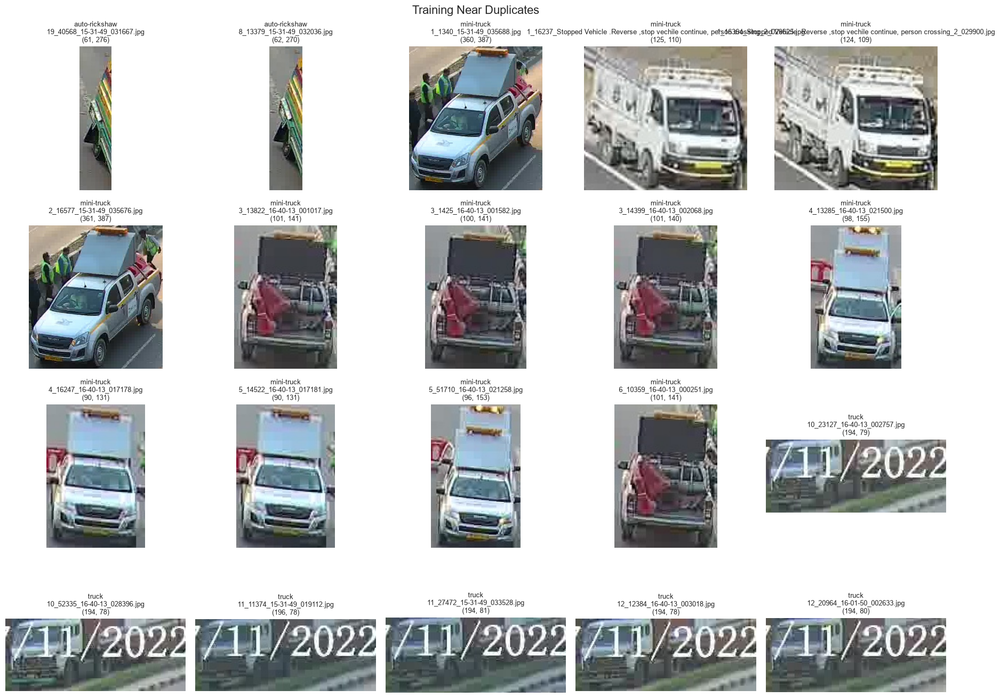

In [27]:
show_flagged_images(
    train_flagged["near_duplicates"],
    "Training Near Duplicates",
    n=20
)

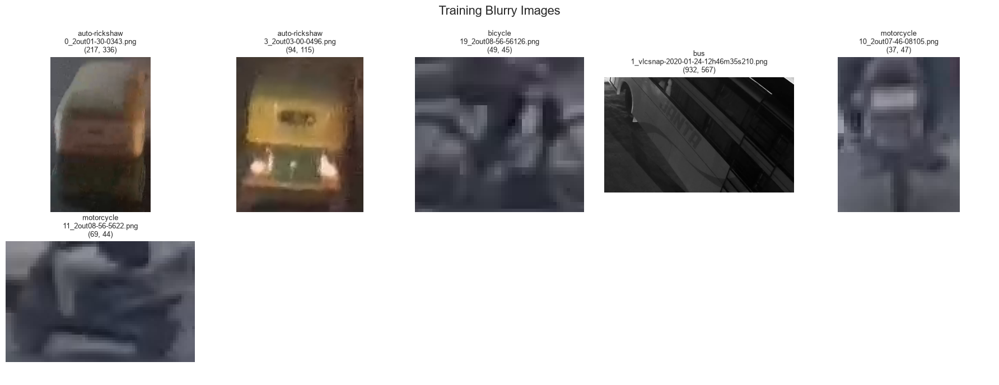

In [28]:
show_flagged_images(
    train_flagged["blurry"],
    "Training Blurry Images",
    n=6
)

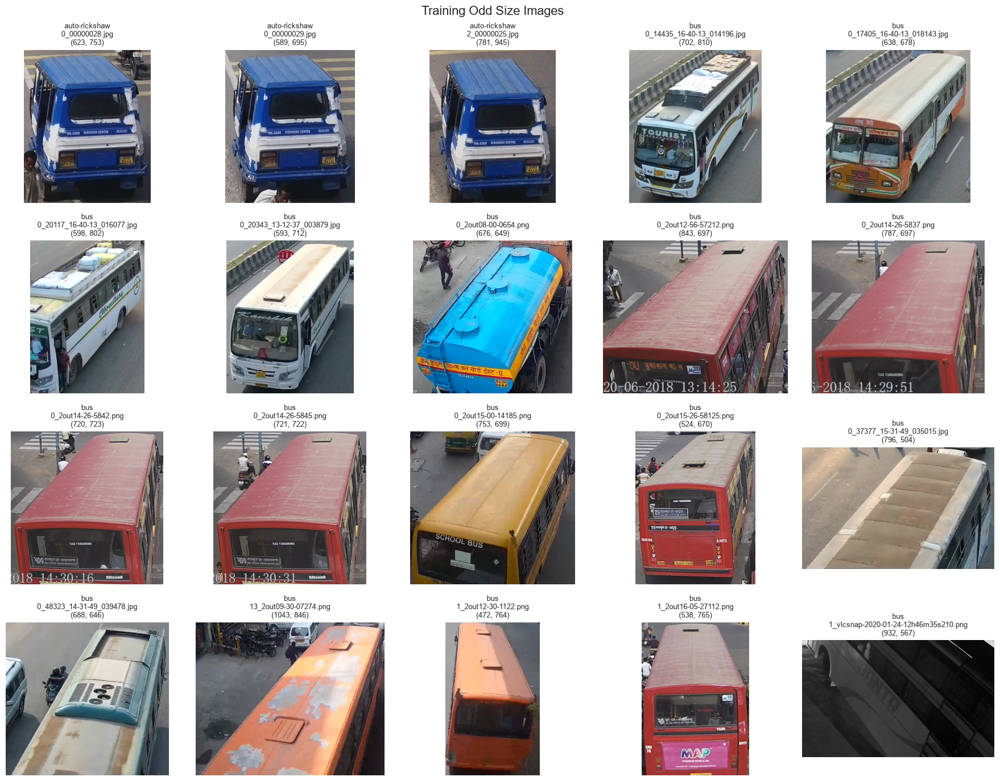

In [29]:
show_flagged_images(
    train_flagged["odd_size"],
    "Training Odd Size Images",
    n=20
)

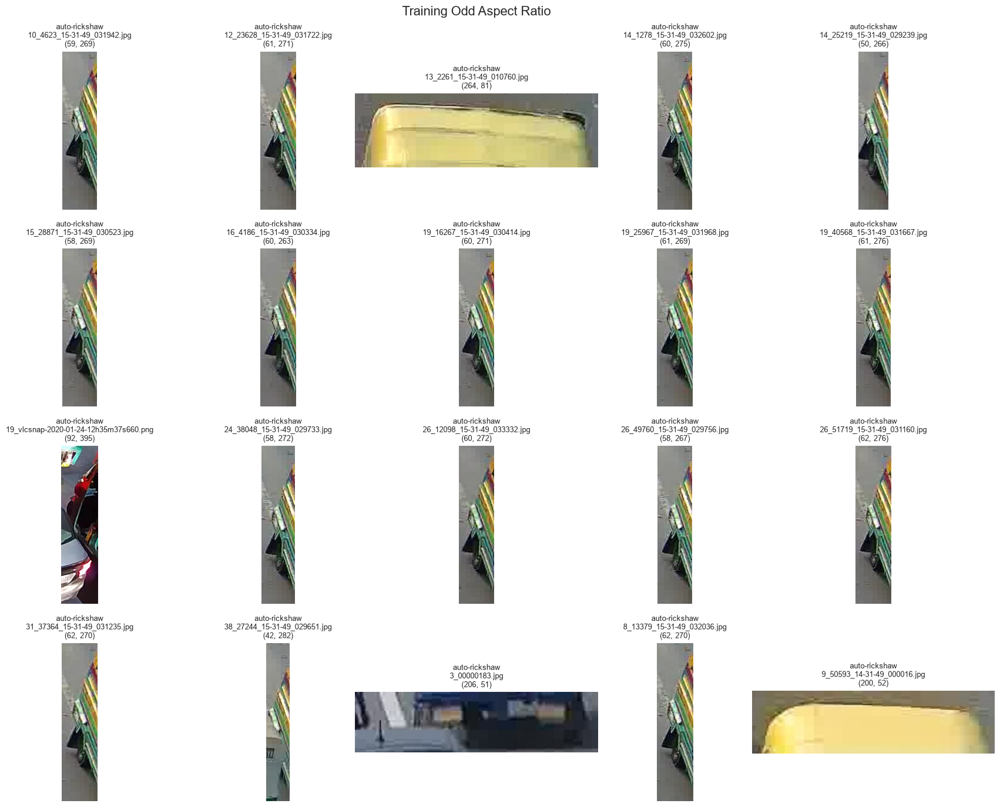

In [30]:
show_flagged_images(
    train_flagged["odd_aspect_ratio"],
    "Training Odd Aspect Ratio",
    n=20
)

In [32]:
import pandas as pd
from pathlib import Path

OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

# Record confirmed exclusions here.
# We will add actual image paths only after verifying them.
exclusions = []

exclusion_df = pd.DataFrame(
    exclusions,
    columns=["path", "reason"]
)

exclusion_df.to_csv(
    OUTPUT_DIR / "cleaning_exclusions.csv",
    index=False
)

print("Cleaning manifest saved.")
print("Confirmed exclusions:", len(exclusion_df))

Cleaning manifest saved.
Confirmed exclusions: 0


In [33]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

excluded_paths = set()

train_files = []

for class_dir in sorted(TRAIN_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    for img_path in class_dir.iterdir():
        if img_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        if str(img_path).lower() not in excluded_paths:
            train_files.append({
                "path": str(img_path),
                "label": class_dir.name
            })

train_df = pd.DataFrame(train_files)

print("Training images:", len(train_df))
print("\nImages per class:")
print(train_df["label"].value_counts().sort_index())

Training images: 2719

Images per class:
label
auto-rickshaw    448
bicycle          263
bus              213
car              117
e-rickshaw        97
mini-bus          12
mini-truck       387
motorcycle       245
rickshaw          24
tractor           81
truck            481
van              351
Name: count, dtype: int64


### inspect the preprocessing visually

## Preprocessing: Aspect-Ratio Preserving Letterboxing
Implement aspect-ratio preserving resizing (letterboxing) with black padding to prevent geometric distortion of vehicles, followed by qualitative verification across sample images.

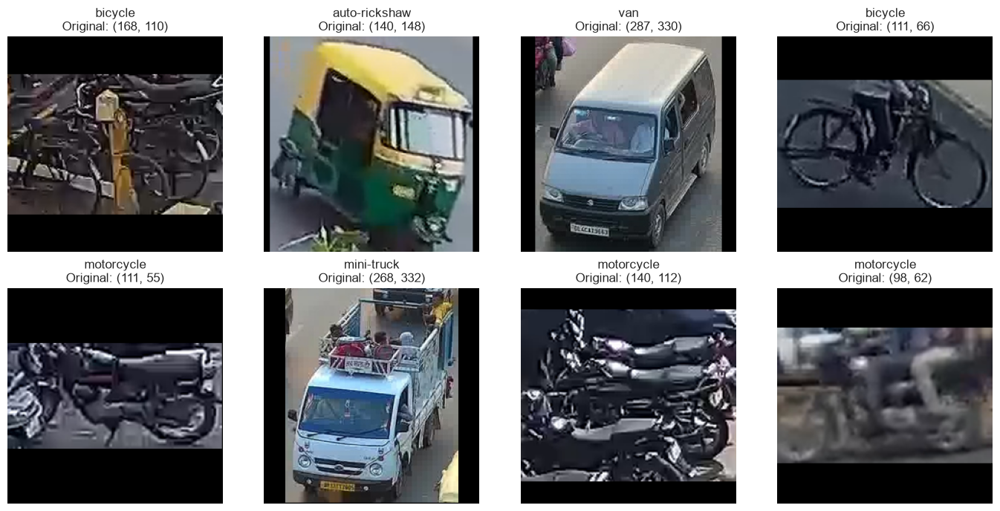

In [35]:
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

def letterbox_image(image, size=224):
    image = image.convert("RGB")

    # Scale image so its largest dimension becomes 224
    scale = min(size / image.width, size / image.height)

    new_width = int(image.width * scale)
    new_height = int(image.height * scale)

    image = image.resize(
        (new_width, new_height),
        Image.Resampling.LANCZOS
    )

    # Create square canvas
    canvas = Image.new("RGB", (size, size), (0, 0, 0))

    # Center the resized image
    x = (size - new_width) // 2
    y = (size - new_height) // 2

    canvas.paste(image, (x, y))

    return canvas


# Show a few different examples
sample_paths = train_df.sample(8, random_state=42)["path"].tolist()

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for ax, path in zip(axes, sample_paths):
    original = Image.open(path).convert("RGB")
    processed = letterbox_image(original)

    ax.imshow(processed)
    ax.set_title(
        f"{Path(path).parent.name}\n"
        f"Original: {original.size}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [36]:
import torch
from torchvision import transforms

# ImageNet statistics because we will use a pretrained ImageNet model
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


class LetterboxTransform:
    def __init__(self, size=224):
        self.size = size

    def __call__(self, image):
        image = image.convert("RGB")

        scale = min(
            self.size / image.width,
            self.size / image.height
        )

        new_width = int(image.width * scale)
        new_height = int(image.height * scale)

        image = image.resize(
            (new_width, new_height),
            Image.Resampling.LANCZOS
        )

        canvas = Image.new(
            "RGB",
            (self.size, self.size),
            (0, 0, 0)
        )

        x = (self.size - new_width) // 2
        y = (self.size - new_height) // 2

        canvas.paste(image, (x, y))

        return canvas


train_transform = transforms.Compose([
    LetterboxTransform(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

val_transform = transforms.Compose([
    LetterboxTransform(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

print("Transforms created successfully.")

Transforms created successfully.


In [37]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class VehicleDataset(Dataset):
    def __init__(self, dataframe, transform=None, class_to_idx=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.class_to_idx = class_to_idx

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image = Image.open(row["path"]).convert("RGB")
        label = self.class_to_idx[row["label"]]

        if self.transform:
            image = self.transform(image)

        return image, label

In [38]:
classes = sorted(train_df["label"].unique())

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(classes)
}

idx_to_class = {
    idx: class_name
    for class_name, idx in class_to_idx.items()
}

print("Classes:")
for idx, class_name in idx_to_class.items():
    print(idx, "->", class_name)

Classes:
0 -> auto-rickshaw
1 -> bicycle
2 -> bus
3 -> car
4 -> e-rickshaw
5 -> mini-bus
6 -> mini-truck
7 -> motorcycle
8 -> rickshaw
9 -> tractor
10 -> truck
11 -> van


In [39]:
val_files = []

for class_dir in sorted(VAL_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    for img_path in class_dir.iterdir():
        if img_path.suffix.lower() in IMAGE_EXTENSIONS:
            val_files.append({
                "path": str(img_path),
                "label": class_dir.name
            })

val_df = pd.DataFrame(val_files)

print("Validation images:", len(val_df))
print("\nImages per class:")
print(val_df["label"].value_counts().sort_index())

Validation images: 765

Images per class:
label
auto-rickshaw    137
bicycle           69
bus               71
car               35
e-rickshaw         6
mini-bus           1
mini-truck       102
motorcycle        69
rickshaw          12
tractor            3
truck            157
van              103
Name: count, dtype: int64


In [40]:
train_dataset = VehicleDataset(
    train_df,
    transform=train_transform,
    class_to_idx=class_to_idx
)

val_dataset = VehicleDataset(
    val_df,
    transform=val_transform,
    class_to_idx=class_to_idx
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

Train dataset: 2719
Validation dataset: 765


In [41]:
image, label = train_dataset[0]

print("Image tensor shape:", image.shape)
print("Label:", label)
print("Class:", idx_to_class[label])
print("Data type:", image.dtype)

Image tensor shape: torch.Size([3, 224, 224])
Label: 0
Class: auto-rickshaw
Data type: torch.float32
